# Boiling point of water vs altitude: vapour-pressure formulas checked against IAPWS-IF97

**The question.** How well does a simple barometric (vapour-pressure) formula predict the boiling
temperature of water at different altitudes, when compared with a reference saturation curve?

**What runs.** A grid of altitudes from 0 to 4000 m. For each altitude, the standard-atmosphere
pressure is computed and then inverted to a boiling temperature by three routes:

1. **Constant-latent-heat Clausius-Clapeyron**, anchored at 373.124 K and 101325 Pa.
2. **Temperature-dependent-latent-heat Clausius-Clapeyron**, integrated numerically from IAPWS-IF97 latent heat.
3. **Antoine equation**, with three constants fitted on 273.15-363.15 K and tested on a held-out band at 363.15-373.15 K.

Each route is compared with the IAPWS-IF97 saturation curve. The notebook also checks the Clapeyron
equation at saturation (ideal vapour, Z_v-corrected and Z_v-plus-liquid volumes, plus two independent
curves), cross-checks the result against a 100 m equation-derived reference table, and ends with a
results table and plots.

**Data.** `mini_demo_data.json` holds the 41-row 100 m equation-derived reference table. It is read from
GitHub, with a local fallback. No measured boiling records are used; every comparison is model against reference.

## Install dependencies

On Colab the core scientific packages are already installed, so they are skipped. Locally they are installed at Colab's exact versions. `iapws` and `loguru` are not on Colab and are always installed.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# Not pre-installed on Colab: always install. iapws is installed without its dependencies so that it cannot pull in a second numpy.
_pip('--no-deps', 'iapws==1.5.5')
_pip('loguru==0.8.0')

# numpy, scipy, matplotlib: pre-installed on Colab, install locally only, at Colab's exact versions
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')


## Imports and figure style

The original import block is kept as written. The figure style block is the run's shared style.

In [2]:
from __future__ import annotations

import csv
import json
import math
import resource
import sys
import time
from pathlib import Path

import numpy as np
from iapws import IAPWS95, IAPWS97
from loguru import logger
from scipy.integrate import cumulative_trapezoid
from scipy.optimize import least_squares

import matplotlib.pyplot as plt

# One colour per role, the same in every notebook of this run and in the paper's figures.
COLOURS = {
    "method": "#0173B2",  # the paper's own method, model or condition
    "baseline": "#949494",  # the main baseline, control or reference
    "other_1": "#DE8F05",  # the first further comparator
    "other_2": "#029E73",  # the second
    "other_3": "#CC78BC",  # the third
    "other_4": "#CA9161",  # the fourth
    "other_5": "#56B4E9",  # the fifth
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["CMU Serif", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#CCCCCC",
    "grid.alpha": 0.6,
    "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=list(COLOURS.values())),
    "image.cmap": "cividis",
    "legend.frameon": False,
    "figure.constrained_layout.use": True,
    "figure.dpi": 120,
})


## Load the data

`mini_demo_data.json` is read from the GitHub URL. If the network is unavailable, the local copy in this folder is used.

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-afc680-barometric-formula-predicts-waters/main/round-2/experiment-4/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")


In [4]:
data = load_data()
print(f"Loaded {len(data['datasets'][0]['examples'])} reference rows")


GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Loaded 41 reference rows


## Config: tunable parameters

The values below are the original script's values, so the notebook reproduces the full run. For a quicker test, reduce them: `ALTITUDE_STEP_M` sets the grid spacing, and the fit and table sizes set the work per route.

In [5]:
# ---- Config: tunable parameters ----
ALTITUDE_STEP_M = 50     # altitude grid step, m (original: 50 -> 81 altitudes, 0-4000 m)
ANTOINE_N_MAIN = 91        # Antoine fit points, 273.15-363.15 K (original: 91)
ANTOINE_N_SENS = 81        # sensitivity Antoine fit points, 273.15-353.15 K (original: 81)
TD_TABLE_N = 10081           # temperature-dependent-L table points (original: 10081, 0.01 K step)
CLAP_SWEEP_N = 101          # Clapeyron sweep points, 273.15-373.15 K (original: 101)

# Working folder: the notebook's own folder (the original script used its own folder)
WS = Path.cwd()
LOG_DIR = WS / "logs"
RES_DIR = WS / "results"
for _d in (LOG_DIR, RES_DIR):
    _d.mkdir(parents=True, exist_ok=True)

logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
logger.add(LOG_DIR / "run.log", rotation="30 MB", level="DEBUG")

# Cap CPU time as the original script did; ignored where the platform refuses it
try:
    resource.setrlimit(resource.RLIMIT_CPU, (3600, 3600))
except (ValueError, OSError) as exc:
    logger.warning(f"Could not set CPU-time limit: {exc}")


## Constants and reference grid

Physical constants, the altitude grid, the fit and held-out ranges, and the prior-screen regression targets.

In [6]:
# ---- constants -------------------------------------------------------------
R_V = 461.5                 # J/(kg K), specific gas constant of water vapour
T0 = 373.124                # K, normal boiling point anchor
P0 = 101325.0               # Pa
T_TRIPLE = 273.16
T_CRIT = 373.946
GRID_H = np.arange(0, 4001, ALTITUDE_STEP_M).astype(float)   # altitudes, m (81 points at the original 50 m step)
FIT_LO, FIT_HI = 273.15, 363.15                  # Antoine fit range (K)
HELD_LO, HELD_HI = 363.15, 373.15                # held-out band (K), by Tb_ref
SENS_FIT_HI = 353.15                             # sensitivity fit upper limit (K)
SENS_HELD_LO = 353.15                            # sensitivity held-out lower (K)
BISECT_TOL = 1e-9           # K
SURVIVAL_MAX_K = 0.6        # max full-grid error for survival, K
CL_TOL = 0.01               # Clapeyron tolerance (relative)
DT_DIFF = 0.01              # K, step for dPs/dT
ANTOINE_P0 = (10.19625, 1730.63, -39.724)   # log10(Pa), B, C(K), NIST water, converted

# prior-screen regression targets (from the plan's prior results)
REG_TARGETS = {
    "constant_L_max_K": 0.278,
    "constant_L_rms_K": 0.152,
    "td_L_max_K": 0.177,
    "td_L_rms_K": 0.108,
    "antoine_in_sample_max_K": 0.0042,
    "antoine_in_sample_rms_K": 0.0022,
    "clapeyron_ideal_max_pct": 1.59,
}
REG_TOL_K = 0.005
REG_TOL_PCT = 0.05

# Cross-check input: the 100 m reference table is the `data` variable loaded above.


def _rel(path: Path) -> str:
    """Workspace-relative path for logs, so no absolute server path is written."""
    return str(path.relative_to(WS))


## Standard atmosphere and the IAPWS-IF97 reference

The standard-atmosphere pressure and temperature at altitude, and the IAPWS-IF97 saturation curve. The reference boiling temperature is found by bisection on the saturation pressure.

In [7]:
# ---- standard atmosphere ------------------------------------------------------
def p_std(h_m: float) -> float:
    """U.S. Standard Atmosphere 1976 troposphere pressure, Pa."""
    return 101325.0 * (1.0 - 2.25577e-5 * h_m) ** 5.25588


def t_std(h_m: float) -> float:
    """U.S. Standard Atmosphere 1976 troposphere temperature, K."""
    return 288.15 - 0.0065 * h_m


# ---- reference: IAPWS-IF97 region 4 (saturation) -------------------------------
def ps_ref(T: float) -> float:
    """Saturation pressure, Pa (IAPWS-IF97 region 4)."""
    return IAPWS97(T=T, x=0).P * 1e6


def sat_if97(T: float) -> dict:
    """Saturation properties at T from IF97: P (Pa), h_fg (J/kg), rho_l, rho_v (kg/m3)."""
    liq = IAPWS97(T=T, x=0)
    vap = IAPWS97(T=T, x=1)
    return {
        "P": vap.P * 1e6,
        "hfg": (vap.h - liq.h) * 1e3,
        "rho_l": liq.rho,
        "rho_v": vap.rho,
    }


def invert_T(p_func, p: float, lo: float = T_TRIPLE, hi: float = T_CRIT) -> float:
    """Bisection: find T with p_func(T) = p, to width BISECT_TOL K."""
    a, b = lo, hi
    if not (p_func(a) <= p <= p_func(b)):
        raise ValueError(f"target pressure {p} Pa outside bracket")
    while b - a > BISECT_TOL:
        m = 0.5 * (a + b)
        if p_func(m) < p:
            a = m
        else:
            b = m
    return 0.5 * (a + b)


## The three vapour-pressure routes

Each route is a saturation-pressure function `P(T)`. Route 1 uses a constant latent heat. Route 2 integrates the temperature-dependent latent heat on a fine temperature grid. Route 3 fits the Antoine constants on the in-sample range by least squares. The fit is repeated from its own solution to check convergence.

In [8]:
# ---- route 1: constant-L Clausius-Clapeyron ---------------------------------------
def make_route_const(L_const: float):
    def p_route(T: float) -> float:
        return P0 * math.exp(-(L_const / R_V) * (1.0 / T - 1.0 / T0))
    return p_route


# ---- route 2: temperature-dependent-L Clausius-Clapeyron -----------------------------
def build_td_table() -> tuple[np.ndarray, np.ndarray]:
    """Integrate dln p/dT = h_fg(T)/(R_v T^2) on a fine grid, anchored at T0, P0."""
    Tg = np.linspace(273.15, 373.95, TD_TABLE_N)  # original: 10081 points, step 0.01 K
    hfg = np.array([sat_if97(float(T))["hfg"] for T in Tg])
    f = hfg / (R_V * Tg ** 2)
    F = cumulative_trapezoid(f, Tg, initial=0.0)
    F0 = float(np.interp(T0, Tg, F))
    lnp = math.log(P0) + (F - F0)
    return Tg, lnp


def make_route_td(Tg: np.ndarray, lnp: np.ndarray):
    def p_route(T: float) -> float:
        return math.exp(float(np.interp(T, Tg, lnp)))
    return p_route


# ---- route 3: Antoine ---------------------------------------------------------------
def antoine_P(T: float, A: float, B: float, C: float) -> float:
    return 10.0 ** (A - B / (T + C))


def make_route_antoine(A: float, B: float, C: float):
    def p_route(T: float) -> float:
        return antoine_P(T, A, B, C)
    return p_route


def fit_antoine(T_lo: float, T_hi: float, n: int, label: str) -> dict:
    """Fit log10(Ps) = A - B/(T+C) on n evenly spaced reference temperatures."""
    T = np.linspace(T_lo, T_hi, n)
    logp = np.array([math.log10(ps_ref(float(t))) for t in T])

    def resid(x: np.ndarray) -> np.ndarray:
        return x[0] - x[1] / (T + x[2]) - logp

    fit = least_squares(
        resid, x0=np.array(ANTOINE_P0, dtype=float),
        xtol=1e-15, ftol=1e-15, gtol=1e-15, max_nfev=20000,
    )
    # convergence check: refit from the solution, the cost must not change beyond 1e-10
    refit = least_squares(
        resid, x0=fit.x, xtol=1e-15, ftol=1e-15, gtol=1e-15, max_nfev=20000,
    )
    cost_change = abs(float(refit.cost) - float(fit.cost))
    param_change = float(np.max(np.abs(refit.x - fit.x)))
    converged = bool(fit.success and refit.success and cost_change < 1e-10)
    rms_log = float(np.sqrt(np.mean(fit.fun ** 2)))
    logger.info(
        f"Antoine fit [{label}] n={n} status={fit.status} success={fit.success} "
        f"A={fit.x[0]:.6f} B={fit.x[1]:.4f} C={fit.x[2]:.4f} "
        f"rms_log10={rms_log:.3e} cost_change_refit={cost_change:.2e} "
        f"param_change_refit={param_change:.2e} converged={converged}"
    )
    return {
        "A": float(fit.x[0]), "B": float(fit.x[1]), "C": float(fit.x[2]),
        "n_points": int(n), "T_range_K": [float(T_lo), float(T_hi)],
        "status": int(fit.status), "success": bool(fit.success),
        "nfev": int(fit.nfev), "cost": float(fit.cost),
        "cost_change_on_refit": cost_change, "param_change_on_refit": param_change,
        "converged": converged, "rms_log10_residual": rms_log,
    }


## Metrics and the Clapeyron residual

`err_stats` summarises errors on a mask of grid points. `clap_point` computes the Clapeyron residual `r = (dPs/dT) T Dv / L - 1` at one saturation temperature, for three vapour-volume choices and two independent saturation curves (Antoine and IAPWS-95).

In [9]:
# ---- metrics -------------------------------------------------------------------------
def err_stats(e: np.ndarray, h: np.ndarray, mask: np.ndarray) -> dict:
    ee = e[mask]
    hh = h[mask]
    if ee.size == 0:
        return {"n": 0}
    i = int(np.argmax(np.abs(ee)))
    last = int(np.argmax(h))
    return {
        "n": int(mask.sum()),
        "rms_K": float(np.sqrt(np.mean(ee ** 2))),
        "max_abs_K": float(np.abs(ee).max()),
        "altitude_of_max_m": float(hh[i]),
        "bias_K": float(np.mean(ee)),
        "err_at_4000m_K": float(e[last]),
    }


def dpdt(fn, T: float, lo: float, hi: float, h: float = DT_DIFF) -> float:
    """Central difference for dPs/dT; one-sided at the ends of the valid range."""
    if T - h < lo:
        return (fn(T + h) - fn(T)) / h
    if T + h > hi:
        return (fn(T) - fn(T - h)) / h
    return (fn(T + h) - fn(T - h)) / (2.0 * h)


def p95(T: float) -> float:
    return IAPWS95(T=T, x=0).P * 1e6


def clap_point(T: float, A: float, B: float, C: float) -> dict:
    """Clapeyron residuals r = (dPs/dT) T Dv / L - 1 at saturation temperature T."""
    Ps = ps_ref(T)
    dPdT = dpdt(ps_ref, T, T_TRIPLE, T_CRIT)
    s = sat_if97(T)
    L = s["hfg"]
    Zv = Ps / (s["rho_v"] * R_V * T)
    Dv_A = R_V * T / Ps                  # ideal vapour
    Dv_B = Zv * R_V * T / Ps             # real-vapour factor Z_v
    Dv_C = 1.0 / s["rho_v"] - 1.0 / s["rho_l"]   # Z_v plus liquid term
    rA = dPdT * T * Dv_A / L - 1.0
    rB = dPdT * T * Dv_B / L - 1.0
    rC = dPdT * T * Dv_C / L - 1.0

    # independent curve 1: Antoine derivative, dP/dT = P ln10 B/(T+C)^2
    P_ant = antoine_P(T, A, B, C)
    dPdT_ant = P_ant * math.log(10.0) * B / (T + C) ** 2
    rB_ant = dPdT_ant * T * Dv_B / L - 1.0

    # independent curve 2: IAPWS-95 saturation (its own P, L, rho, Z_v, dP/dT)
    v95 = IAPWS95(T=T, x=1)
    l95 = IAPWS95(T=T, x=0)
    P95 = v95.P * 1e6
    L95 = (v95.h - l95.h) * 1e3
    dPdT95 = dpdt(p95, T, T_TRIPLE, T_CRIT)
    Zv95 = P95 / (v95.rho * R_V * T)
    Dv95_B = Zv95 * R_V * T / P95
    rB_95 = dPdT95 * T * Dv95_B / L95 - 1.0
    Dv95_C = 1.0 / v95.rho - 1.0 / l95.rho
    rC_95 = dPdT95 * T * Dv95_C / L95 - 1.0

    return {
        "T_K": T, "Ps_Pa": Ps, "dPsdT_IF97_Pa_per_K": dPdT, "hfg_IF97_J_per_kg": L,
        "rho_v_IF97": s["rho_v"], "rho_l_IF97": s["rho_l"], "Zv_IF97": Zv,
        "rA_ideal_vapour": rA, "rB_Zv_corrected": rB, "rC_Zv_plus_liquid": rC,
        "dPsdT_Antoine_Pa_per_K": dPdT_ant, "rB_Antoine_derivative": rB_ant,
        "dPsdT_IAPWS95_Pa_per_K": dPdT95, "hfg_IAPWS95_J_per_kg": L95,
        "Zv_IAPWS95": Zv95, "rB_IAPWS95_derivative": rB_95, "rC_IAPWS95_derivative": rC_95,
    }


## Step 1: sanity checks

The reference and the standard atmosphere are checked against known values: the sea-level boiling point, the triple-point pressure, the 4000 m standard pressure, and the vapour compressibility near 373 K. The notebook stops if any check fails.

In [10]:
t_start = time.time()
logger.info("=== Held-out test of vapour-pressure routes + Clapeyron check ===")

# ---- Step 1: sanity checks ---------------------------------------------------
sanity = {}
tb_sea = invert_T(ps_ref, P0)
sanity["Tb_ref_sea_level_K"] = tb_sea
sanity["Tb_ref_sea_level_ok"] = bool(abs(tb_sea - 373.124) <= 0.01)
tp = ps_ref(T_TRIPLE)
sanity["Ps_triple_Pa"] = tp
sanity["Ps_triple_ok"] = bool(abs(tp - 611.657) <= 0.01)
p4000 = p_std(4000.0)
sanity["p_std_4000m_Pa"] = p4000
sanity["p_std_4000m_ok"] = bool(abs(p4000 - 61640.0) <= 20.0)
zv373 = sat_if97(373.15)
Zv373 = ps_ref(373.15) / (zv373["rho_v"] * R_V * 373.15)
sanity["Zv_373_15K"] = Zv373
sanity["Zv_373_15K_ok"] = bool(0.97 <= Zv373 <= 0.99)
sanity["all_ok"] = bool(
    sanity["Tb_ref_sea_level_ok"] and sanity["Ps_triple_ok"]
    and sanity["p_std_4000m_ok"] and sanity["Zv_373_15K_ok"]
)
logger.info(f"Sanity: {json.dumps(sanity, default=float)}")
if not sanity["all_ok"]:
    logger.error("Step 1 sanity checks failed; see summary. Stopping.")
    raise SystemExit(2)


14:43:23|INFO   |=== Held-out test of vapour-pressure routes + Clapeyron check ===


14:43:23|INFO   |Sanity: {"Tb_ref_sea_level_K": 373.12430000070515, "Tb_ref_sea_level_ok": true, "Ps_triple_Pa": 611.6570000106653, "Ps_triple_ok": true, "p_std_4000m_Pa": 61640.20644405919, "p_std_4000m_ok": true, "Zv_373_15K": 0.9846000632619707, "Zv_373_15K_ok": true, "all_ok": true}


## Step 2: build the routes

Build the constant-L route, the temperature-dependent-L table, and the two Antoine fits (main range and sensitivity range).

In [11]:
# ---- Step 2: build routes ------------------------------------------------------
L_const = sat_if97(T0)["hfg"]
logger.info(f"Constant latent heat at {T0} K: L = {L_const:.1f} J/kg")
p_const = make_route_const(L_const)

logger.info(f"Building temperature-dependent-L table ({TD_TABLE_N} points, IF97)")
t_tab = time.time()
Tg, lnp_tab = build_td_table()
logger.info(f"TD-L table built in {time.time() - t_tab:.1f} s, {Tg.size} points")
p_td = make_route_td(Tg, lnp_tab)

# Antoine: fitted on the in-sample range (main) and the sensitivity range
ant_main = fit_antoine(FIT_LO, FIT_HI, ANTOINE_N_MAIN, f"273.15-363.15 K, n={ANTOINE_N_MAIN}")
ant_sens = fit_antoine(FIT_LO, SENS_FIT_HI, ANTOINE_N_SENS, f"273.15-353.15 K, n={ANTOINE_N_SENS} (sensitivity)")
p_ant = make_route_antoine(ant_main["A"], ant_main["B"], ant_main["C"])
p_ant_sens = make_route_antoine(ant_sens["A"], ant_sens["B"], ant_sens["C"])


14:43:23|INFO   |Constant latent heat at 373.124 K: L = 2256541.5 J/kg


14:43:23|INFO   |Building temperature-dependent-L table (10081 points, IF97)


14:43:25|INFO   |TD-L table built in 2.0 s, 10081 points


14:43:25|INFO   |Antoine fit [273.15-363.15 K, n=91] n=91 status=3 success=True A=10.224956 B=1746.8982 C=-38.3351 rms_log10=2.641e-04 cost_change_refit=0.00e+00 param_change_refit=0.00e+00 converged=True


14:43:25|INFO   |Antoine fit [273.15-353.15 K, n=81 (sensitivity)] n=81 status=3 success=True A=10.243684 B=1756.8563 C=-37.5838 rms_log10=2.005e-04 cost_change_refit=0.00e+00 param_change_refit=0.00e+00 converged=True


## Step 3: invert each route on the altitude grid

For each altitude, the standard pressure is inverted through the reference and each route to a boiling temperature. Errors are the route minus the reference. Points are tagged in-sample (`Tb_ref` below 363.15 K) or held-out (363.15-373.15 K). The constant-L result is also checked against its closed form.

In [12]:
# ---- Step 3: grid inversions ---------------------------------------------------
p_grid = np.array([p_std(h) for h in GRID_H])
tb_ref = np.array([invert_T(ps_ref, p) for p in p_grid])
tb_const = np.array([invert_T(p_const, p) for p in p_grid])
tb_td = np.array([invert_T(p_td, p) for p in p_grid])
tb_ant = np.array([invert_T(p_ant, p) for p in p_grid])
tb_ant_sens = np.array([invert_T(p_ant_sens, p) for p in p_grid])

# analytic cross-check of the constant-L inversion (bisection vs closed form)
tb_const_analytic = np.array(
    [1.0 / (1.0 / T0 - math.log(p / P0) * R_V / L_const) for p in p_grid]
)
analytic_gap = float(np.max(np.abs(tb_const - tb_const_analytic)))
logger.info(f"Constant-L bisection vs closed form: max gap {analytic_gap:.2e} K")

e_const = tb_const - tb_ref
e_td = tb_td - tb_ref
e_ant = tb_ant - tb_ref
e_ant_sens = tb_ant_sens - tb_ref

in_sample = (tb_ref >= FIT_LO) & (tb_ref < FIT_HI)
held_out = (tb_ref >= HELD_LO) & (tb_ref <= HELD_HI)
full = np.ones_like(tb_ref, dtype=bool)
held_sens = (tb_ref >= SENS_HELD_LO) & (tb_ref <= HELD_HI)
band = np.where(in_sample, "in_sample", "held_out")
logger.info(
    f"Grid: {GRID_H.size} points; in_sample={int(in_sample.sum())}, held_out={int(held_out.sum())} "
    f"(Tb_ref 363.15-373.15 K), held_out altitude range "
    f"{GRID_H[held_out].min():.0f}-{GRID_H[held_out].max():.0f} m"
)

routes = {
    "constant_L_clausius_clapeyron": e_const,
    "td_L_clausius_clapeyron": e_td,
    "antoine": e_ant,
}
route_stats = {}
for name, e in routes.items():
    route_stats[name] = {
        "full_grid": err_stats(e, GRID_H, full),
        "in_sample_tagged": err_stats(e, GRID_H, in_sample),
        "held_out": err_stats(e, GRID_H, held_out),
    }
    logger.info(
        f"{name}: full max={route_stats[name]['full_grid']['max_abs_K']:.4f} K "
        f"rms={route_stats[name]['full_grid']['rms_K']:.4f} K | "
        f"held-out rms={route_stats[name]['held_out']['rms_K']:.5f} K "
        f"max={route_stats[name]['held_out']['max_abs_K']:.5f} K"
    )
route_stats["antoine"]["fit_range_inversion_residual"] = err_stats(e_ant, GRID_H, in_sample)

sens_stats = {
    "fit_range_K": [FIT_LO, SENS_FIT_HI],
    "held_out_range_K": [SENS_HELD_LO, HELD_HI],
    "antoine_params": {k: ant_sens[k] for k in ("A", "B", "C")},
    "held_out": err_stats(e_ant_sens, GRID_H, held_sens),
    "not_ranked": True,
}
logger.info(
    f"Sensitivity (Antoine fit 273.15-353.15 K): held-out [353.15,373.15] n={sens_stats['held_out']['n']} "
    f"rms={sens_stats['held_out']['rms_K']:.5f} K max={sens_stats['held_out']['max_abs_K']:.5f} K"
)


14:43:25|INFO   |Constant-L bisection vs closed form: max gap 3.57e-10 K


14:43:25|INFO   |Grid: 81 points; in_sample=21, held_out=60 (Tb_ref 363.15-373.15 K), held_out altitude range 0-2950 m


14:43:25|INFO   |constant_L_clausius_clapeyron: full max=0.2798 K rms=0.1532 K | held-out rms=0.10778 K max=0.19407 K


14:43:25|INFO   |td_L_clausius_clapeyron: full max=0.1765 K rms=0.1077 K | held-out rms=0.08279 K max=0.13741 K


14:43:25|INFO   |antoine: full max=0.0856 K rms=0.0548 K | held-out rms=0.06126 K max=0.08562 K


14:43:25|INFO   |Sensitivity (Antoine fit 273.15-353.15 K): held-out [353.15,373.15] n=81 rms=0.09244 K max=0.13250 K


## Step 4: regression against the prior screen

The full-grid and in-sample numbers are compared with the values recorded in the prior screen. A mismatch is reported, not hidden. The Antoine in-sample target is the one the source flags as not reproduced.

In [13]:
# ---- Step 4: regression against prior numbers ----------------------------------------
fg = {n: route_stats[n]["full_grid"] for n in routes}
regression = {
    "constant_L_max_K": {"expected": REG_TARGETS["constant_L_max_K"], "got": fg["constant_L_clausius_clapeyron"]["max_abs_K"], "tol": REG_TOL_K},
    "constant_L_rms_K": {"expected": REG_TARGETS["constant_L_rms_K"], "got": fg["constant_L_clausius_clapeyron"]["rms_K"], "tol": REG_TOL_K},
    "td_L_max_K": {"expected": REG_TARGETS["td_L_max_K"], "got": fg["td_L_clausius_clapeyron"]["max_abs_K"], "tol": REG_TOL_K},
    "td_L_rms_K": {"expected": REG_TARGETS["td_L_rms_K"], "got": fg["td_L_clausius_clapeyron"]["rms_K"], "tol": REG_TOL_K},
    "antoine_in_sample_max_K": {"expected": REG_TARGETS["antoine_in_sample_max_K"], "got": route_stats["antoine"]["in_sample_tagged"]["max_abs_K"], "tol": REG_TOL_K},
    "antoine_in_sample_rms_K": {"expected": REG_TARGETS["antoine_in_sample_rms_K"], "got": route_stats["antoine"]["in_sample_tagged"]["rms_K"], "tol": REG_TOL_K},
}
for k, v in regression.items():
    v["pass"] = bool(abs(v["got"] - v["expected"]) <= v["tol"])
    logger.info(f"Regression {k}: expected {v['expected']} got {v['got']:.5f} pass={v['pass']}")


14:43:25|INFO   |Regression constant_L_max_K: expected 0.278 got 0.27982 pass=True


14:43:25|INFO   |Regression constant_L_rms_K: expected 0.152 got 0.15324 pass=True


14:43:25|INFO   |Regression td_L_max_K: expected 0.177 got 0.17649 pass=True


14:43:25|INFO   |Regression td_L_rms_K: expected 0.108 got 0.10773 pass=True


14:43:25|INFO   |Regression antoine_in_sample_max_K: expected 0.0042 got 0.03576 pass=False


14:43:25|INFO   |Regression antoine_in_sample_rms_K: expected 0.0022 got 0.02958 pass=False


## Step 5: ranking

Routes whose full-grid maximum error stays within 0.6 K are ranked by held-out RMS error.

In [14]:
# ---- Step 5: ranking ----------------------------------------------------------------
ranking_rows = []
for name in routes:
    fgs = route_stats[name]["full_grid"]
    survives = fgs["max_abs_K"] <= SURVIVAL_MAX_K
    ranking_rows.append({
        "route": name,
        "held_out_rms_K": route_stats[name]["held_out"]["rms_K"],
        "full_grid_max_abs_K": fgs["max_abs_K"],
        "survives_0_6K_rule": bool(survives),
    })
survivors = [r for r in ranking_rows if r["survives_0_6K_rule"]]
survivors.sort(key=lambda r: r["held_out_rms_K"])
ranking = [
    {"rank": i + 1, **r} for i, r in enumerate(survivors)
]
logger.info(f"Ranking (survivors, by held-out RMS): {[r['route'] for r in ranking]}")


14:43:25|INFO   |Ranking (survivors, by held-out RMS): ['antoine', 'td_L_clausius_clapeyron', 'constant_L_clausius_clapeyron']


## Step 6: Clapeyron consistency check

The Clapeyron residual is evaluated at the grid saturation temperatures (356-373.15 K) and on a sweep from the triple point to 373.15 K. The Z_v-corrected IF97 residual is near zero by construction, so the independent curves (Antoine and IAPWS-95) carry the test.

In [15]:
# ---- Step 6: Clapeyron check -------------------------------------------------------
t_clap = time.time()
grid_T_clap = sorted(float(t) for t in tb_ref[(tb_ref >= 356.0) & (tb_ref <= 373.15)])
# IAPWS-95 rejects T = 273.15 K (valid from 273.16 K), so the sweep starts at the triple point
sweep_T = [float(t) for t in np.linspace(T_TRIPLE, 373.15, CLAP_SWEEP_N)]
logger.info(f"Clapeyron: {len(grid_T_clap)} grid saturation temperatures (356-373 K), "
            f"{len(sweep_T)} sweep points (273.15-373.15 K)")
clap_grid = [clap_point(T, ant_main["A"], ant_main["B"], ant_main["C"]) for T in grid_T_clap]
clap_sweep = [clap_point(T, ant_main["A"], ant_main["B"], ant_main["C"]) for T in sweep_T]
clap_all = clap_grid + clap_sweep
logger.info(f"Clapeyron points computed in {time.time() - t_clap:.1f} s")

def max_abs(key: str) -> float:
    return float(max(abs(p[key]) for p in clap_all))

max_rA = max_abs("rA_ideal_vapour")
max_rB = max_abs("rB_Zv_corrected")
max_rC = max_abs("rC_Zv_plus_liquid")
max_rB_ant = max_abs("rB_Antoine_derivative")
max_rB_95 = max_abs("rB_IAPWS95_derivative")
max_rC_95 = max_abs("rC_IAPWS95_derivative")
identity_pass = max_rB <= CL_TOL
indep_pass = max(max_rB_ant, max_rB_95) <= CL_TOL
if identity_pass and indep_pass:
    verdict = "holds (largely an identity; the independent-curve residuals also pass)"
elif indep_pass:
    verdict = "partly holds (only the independent-curve residuals pass)"
else:
    verdict = "fails"
clap_summary = {
    "n_points_grid_T_356_373K": len(clap_grid),
    "n_points_sweep_273_373K": len(clap_sweep),
    "max_abs_rA_ideal_vapour": max_rA,
    "max_abs_rB_Zv_corrected": max_rB,
    "max_abs_rC_Zv_plus_liquid": max_rC,
    "max_abs_rB_Antoine_derivative": max_rB_ant,
    "max_abs_rB_IAPWS95_derivative": max_rB_95,
    "max_abs_rC_IAPWS95_derivative": max_rC_95,
    "rA_minus_rB_max_abs": max_rA - max_rB,
    "rA_exceeds_1pct_tolerance": bool(max_rA > CL_TOL),
    "identity_pass_Zv_corrected_IF97": bool(identity_pass),
    "independent_curve_pass": bool(indep_pass),
    "verdict": verdict,
    "identity_caveat": (
        "dP/dT, L and Z_v come from the same IF97 equations, and Dv_B = 1/rho_v "
        "exactly, so the Z_v-corrected IF97 residual is near zero by construction. "
        "The independent-curve residuals (Antoine and IAPWS-95 derivatives) carry "
        "the test."
    ),
    "tolerance_relative": CL_TOL,
}
logger.info(f"Clapeyron: max|rA|={max_rA:.5f} max|rB|={max_rB:.2e} "
            f"max|rB_ant|={max_rB_ant:.5f} max|rB_95|={max_rB_95:.5f} verdict: {verdict}")


14:43:25|INFO   |Clapeyron: 81 grid saturation temperatures (356-373 K), 101 sweep points (273.15-373.15 K)


14:43:28|INFO   |Clapeyron points computed in 2.4 s


14:43:28|INFO   |Clapeyron: max|rA|=0.01626 max|rB|=6.10e-04 max|rB_ant|=0.00920 max|rB_95|=0.00062 verdict: holds (largely an identity; the independent-curve residuals also pass)


## Step 7: cross-check against the 100 m reference table

Each row of `mini_demo_data.json` is compared with the boiling temperature the reference gives at the same altitude. This is consistency between two reference calculations, not validity against measurements.

In [16]:
# ---- Step 7: dataset cross-check --------------------------------------------------
# The original script read data/full_data_out.json; here the same table is the `data` variable.
cross = {"file": "mini_demo_data.json", "status": "not run"}
try:
    dat = data
    rows = dat["datasets"][0]["examples"]
    diffs = []
    for row in rows:
        h = float(json.loads(row["input"])["elevation_m"])
        t_tab_k = float(row["output"]) + 273.15
        t_ref_k = invert_T(ps_ref, p_std(h))
        diffs.append({"elevation_m": h, "dataset_K": t_tab_k, "ref_K": t_ref_k,
                      "ref_minus_dataset_K": t_ref_k - t_tab_k})
    arr = np.array([d["ref_minus_dataset_K"] for d in diffs])
    cross = {
        "file": "mini_demo_data.json",
        "status": "ok",
        "n_rows": len(diffs),
        "dataset_unit_note": "dataset output is in degrees C (metadata_formula_boiling_C column); converted +273.15 to K",
        "max_abs_diff_K": float(np.max(np.abs(arr))),
        "mean_diff_K": float(np.mean(arr)),
        "rows": diffs,
        "interpretation": "consistency between two reference calculations, not validity against measurements",
    }
    logger.info(f"Dataset cross-check: n={len(diffs)} max|diff|={cross['max_abs_diff_K']:.4f} K "
                f"mean={cross['mean_diff_K']:.4f} K")
except (OSError, json.JSONDecodeError, KeyError, ValueError) as exc:
    logger.error(f"Dataset cross-check failed: {exc}")
    cross = {"file": "mini_demo_data.json", "status": f"failed: {exc}"}


14:43:28|INFO   |Dataset cross-check: n=41 max|diff|=0.0625 K mean=-0.0181 K


## Step 8: write outputs

The grid CSV, the Clapeyron JSON, the summary JSON, and the method output files (`method_out.json` and `full_method_out.json`, which are identical here) are written to this folder.

In [17]:
# ---- Step 8: write outputs --------------------------------------------------------------
grid_csv = RES_DIR / "grid_values.csv"
with grid_csv.open("w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["elevation_m", "p_std_Pa", "Tb_ref_K", "Tb_constant_L_K", "Tb_td_L_K",
                "Tb_antoine_K", "err_constant_L_K", "err_td_L_K", "err_antoine_K",
                "err_antoine_sensitivity_K", "tag"])
    for i in range(GRID_H.size):
        w.writerow([f"{GRID_H[i]:.0f}", f"{p_grid[i]:.4f}", f"{tb_ref[i]:.9f}",
                    f"{tb_const[i]:.9f}", f"{tb_td[i]:.9f}", f"{tb_ant[i]:.9f}",
                    f"{e_const[i]:.9f}", f"{e_td[i]:.9f}", f"{e_ant[i]:.9f}",
                    f"{e_ant_sens[i]:.9f}", band[i]])
logger.info(f"Wrote {_rel(grid_csv)}")

clap_path = RES_DIR / "clapeyron.json"
clap_path.write_text(json.dumps({
    "method": "Clapeyron residual r = (dPs/dT) T Dv / L - 1",
    "dPdT_step_K": DT_DIFF,
    "routes": {"A": "ideal vapour Dv = R_v T / Ps", "B": "Z_v corrected Dv = Z_v R_v T / Ps",
               "C": "Z_v plus liquid Dv = 1/rho_v - 1/rho_l"},
    "summary": clap_summary,
    "points": clap_all,
}, indent=2))
logger.info(f"Wrote {_rel(clap_path)}")

summary = {
    "title": "Held-out test of vapour-pressure routes and Clapeyron check",
    "reference": "IAPWS-IF97 region 4 (iapws 1.5.5), saturation pressure",
    "atmosphere": f"U.S. Standard Atmosphere 1976 troposphere pressure, 0-4000 m, {ALTITUDE_STEP_M} m steps ({GRID_H.size} points)",
    "antoine_fit_main": ant_main,
    "antoine_fit_sensitivity": ant_sens,
    "sanity_checks": sanity,
    "regression_against_prior_screen": regression,
    "regression_all_pass": bool(all(v["pass"] for v in regression.values())),
    "grid_counts": {"in_sample_tagged": int(in_sample.sum()), "held_out": int(held_out.sum()),
                    "full": int(full.sum())},
    "route_errors": route_stats,
    "sensitivity_antoine_273_353_fit": sens_stats,
    "ranking_held_out_rms_survivors": ranking,
    "all_routes_survival": ranking_rows,
    "constant_L_bisection_vs_closed_form_max_gap_K": analytic_gap,
    "clapeyron": clap_summary,
    "interpretation_status": (
        "PROVISIONAL: the Antoine regression target (0.0042 K in-sample) did not reproduce; "
        "the executed value is reported, and rankings and verdicts are not interpreted until it is resolved."
        if not all(v["pass"] for v in regression.values()) else "regression targets reproduced"
    ),
    "dataset_cross_check": {k: v for k, v in cross.items() if k != "rows"},
    "runtime_s": time.time() - t_start,
    "provenance": {
        "fallback_used": "none (iapws package used as reference)",
        "measured_data_used": False,
    },
}
summary_path = RES_DIR / "summary.json"
summary_path.write_text(json.dumps(summary, indent=2))
logger.info(f"Wrote {_rel(summary_path)}")

method_out = {
    "metadata": {
        "method_name": "Vapour-pressure routes for water boiling temperature vs altitude",
        "description": f"Model-to-reference comparison against IAPWS-IF97 saturation; one example per {ALTITUDE_STEP_M} m altitude.",
        "reference": "IAPWS-IF97 region 4 (iapws package)",
        "units": {"output": "boiling temperature, K", "predict_*": "boiling temperature, K"},
        "routes": ["constant_L_clausius_clapeyron", "td_L_clausius_clapeyron", "antoine"],
        "antoine_fit_range_K": [FIT_LO, FIT_HI],
        "held_out_range_K": [HELD_LO, HELD_HI],
        "runtime_s": time.time() - t_start,
    },
    "datasets": [{
        "dataset": "altitude_grid_0_4000m_50m_IF97_reference",
        "examples": [],
    }],
}
examples = method_out["datasets"][0]["examples"]
for i in range(GRID_H.size):
    examples.append({
        "input": json.dumps({"elevation_m": float(GRID_H[i])}),
        "output": f"{tb_ref[i]:.6f}",
        "metadata_p_std_Pa": f"{p_grid[i]:.4f}",
        "metadata_split": str(band[i]),
        "metadata_err_constant_L_K": f"{e_const[i]:.6f}",
        "metadata_err_td_L_K": f"{e_td[i]:.6f}",
        "metadata_err_antoine_K": f"{e_ant[i]:.6f}",
        "predict_constant_L_clausius_clapeyron": f"{tb_const[i]:.6f}",
        "predict_td_L_clausius_clapeyron": f"{tb_td[i]:.6f}",
        "predict_antoine": f"{tb_ant[i]:.6f}",
    })
out_path = WS / "method_out.json"
out_path.write_text(json.dumps(method_out, indent=2))
full_path = WS / "full_method_out.json"
full_path.write_text(json.dumps(method_out, indent=2))
logger.info(f"Wrote {_rel(full_path)} (full, {len(examples)} examples)")
logger.info(f"Wrote {_rel(out_path)} with {len(examples)} examples")

logger.info(f"Done in {time.time() - t_start:.1f} s")


14:43:28|INFO   |Wrote results/grid_values.csv


14:43:28|INFO   |Wrote results/clapeyron.json


14:43:28|INFO   |Wrote results/summary.json


14:43:28|INFO   |Wrote full_method_out.json (full, 81 examples)


14:43:28|INFO   |Wrote method_out.json with 81 examples


14:43:28|INFO   |Done in 5.0 s


## Results: table and plots

The table lists each route's errors on the full grid and on the held-out band, and whether it survives the 0.6 K rule. The plots show the signed error against altitude, and the full-grid maximum and held-out RMS per route. Colours follow the run's role palette: the Antoine route is the paper's method, and the other two are comparators.

route                               full max |err| K  full RMS K  held-out RMS K  survives 0.6 K
constant_L_clausius_clapeyron                 0.2798      0.1532         0.10778            True
td_L_clausius_clapeyron                       0.1765      0.1077         0.08279            True
antoine                                       0.0856      0.0548         0.06126            True

Clapeyron max |residual| (%): ideal vapour 1.63, Z_v-corrected 0.061, Z_v plus liquid 0.04, Antoine derivative 0.920, IAPWS-95 derivative 0.062
Regression against prior-screen numbers: some fail (see PROVISIONAL note in summary)
Dataset cross-check max |diff| K: 0.0625


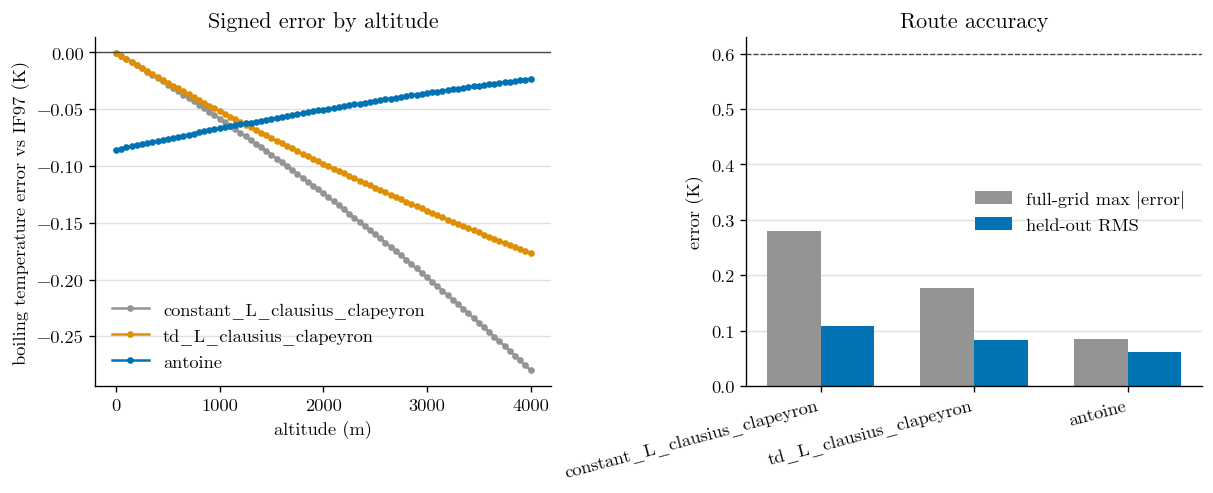

In [18]:
# ---- Results: table and plots ----
print(f"{'route':34s} {'full max |err| K':>17s} {'full RMS K':>11s} {'held-out RMS K':>15s} {'survives 0.6 K':>15s}")
for r in ranking_rows:
    n_ = r["route"]
    fg_ = route_stats[n_]["full_grid"]
    ho_ = route_stats[n_]["held_out"]
    print(f"{n_:34s} {fg_['max_abs_K']:17.4f} {fg_['rms_K']:11.4f} {ho_['rms_K']:15.5f} {str(r['survives_0_6K_rule']):>15s}")
print()
print("Clapeyron max |residual| (%): ideal vapour {:.2f}, Z_v-corrected {:.3f}, Z_v plus liquid {:.2f}, "
      "Antoine derivative {:.3f}, IAPWS-95 derivative {:.3f}".format(
          100 * max_rA, 100 * max_rB, 100 * max_rC, 100 * max_rB_ant, 100 * max_rB_95))
print("Regression against prior-screen numbers:", "all pass" if all(v["pass"] for v in regression.values()) else "some fail (see PROVISIONAL note in summary)")
print("Dataset cross-check max |diff| K:", round(cross.get("max_abs_diff_K", float("nan")), 4))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
names = list(routes)
route_colours = [COLOURS["baseline"], COLOURS["other_1"], COLOURS["method"]]
for name, col in zip(names, route_colours):
    ax1.plot(GRID_H, routes[name], marker="o", ms=3, label=name, color=col)
ax1.axhline(0, color="#444444", lw=0.8)
ax1.set_xlabel("altitude (m)")
ax1.set_ylabel("boiling temperature error vs IF97 (K)")
ax1.set_title("Signed error by altitude")
ax1.legend()

x = np.arange(len(names))
w = 0.35
ax2.bar(x - w / 2, [route_stats[n]["full_grid"]["max_abs_K"] for n in names], w,
        label="full-grid max |error|", color=COLOURS["baseline"])
ax2.bar(x + w / 2, [route_stats[n]["held_out"]["rms_K"] for n in names], w,
        label="held-out RMS", color=COLOURS["method"])
ax2.axhline(SURVIVAL_MAX_K, color="#444444", lw=0.8, ls="--")
ax2.set_xticks(x, names, rotation=15, ha="right")
ax2.set_ylabel("error (K)")
ax2.set_title("Route accuracy")
ax2.legend()
plt.show()


## Interpretation

What the printed table and plots show, on the 0-4000 m grid (81 points) against IAPWS-IF97:

- **Constant-latent-heat Clausius-Clapeyron** has the largest errors: full-grid maximum 0.280 K (at 4000 m) and RMS 0.153 K, with held-out RMS 0.108 K.
- **Temperature-dependent-latent-heat Clausius-Clapeyron** is smaller: maximum 0.177 K, RMS 0.108 K, held-out RMS 0.083 K.
- **Antoine** has the lowest full-grid maximum (0.086 K, at sea level), RMS 0.055 K and held-out RMS 0.061 K.

All three routes stay within the 0.6 K survival rule. Ranked by held-out RMS: Antoine, then TD-L, then constant-L.

**Clapeyron check.** The ideal-vapour residual reaches 1.63 %, above the 1 % tolerance. The Z_v-corrected residual (0.06 %) is near zero by construction, because the same IF97 equations supply the derivative and the volume. The independent curves carry the test: the Antoine derivative (0.92 %) and the IAPWS-95 derivative (0.06 %) both pass the 1 % tolerance, though the Antoine residual is close to it.

**Caveats.** The Antoine in-sample regression target (0.0042 K) did not reproduce here (0.036 K), so the Antoine ranking is PROVISIONAL. The 100 m reference table agrees with the reference calculation to within 0.063 K. No measured boiling records are used, so every number measures agreement with the IAPWS-IF97 model, not with observed boiling points.

**Bottom line.** A simple barometric formula reproduces the IAPWS-IF97 boiling curve to within about 0.3 K over 0-4000 m. The Clapeyron check holds, but mostly as an identity.